# Convolutional neural network for image classification

In [43]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import hashlib
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
import numpy as np
import cv2
tf.keras.utils.set_random_seed(1)
tf.__version__

'2.21.0'

## Loading the images

In [2]:
def display_image(img, title: str = None):
    if len(img.shape) == 2:
        plt.imshow(img, cmap='gray')
    if len(img.shape) == 3:
        if img.shape[2] == 3:
            img_display = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.imshow(img_display)
        elif img.shape[2] == 4:
            plt.imshow(img)

    if title:
        plt.title(title)

    plt.axis('off')
    plt.show()

In [3]:
path = 'drive/Datasets/homer_bart_2.zip'
with zipfile.ZipFile(path, 'r') as zip_object:
    zip_object.extractall('./')

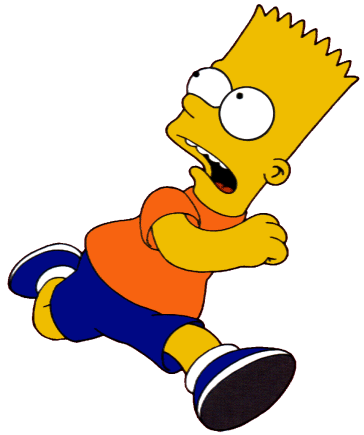

In [4]:
tf.keras.preprocessing.image.load_img('./homer_bart_2/training_set/bart/bart100.bmp')

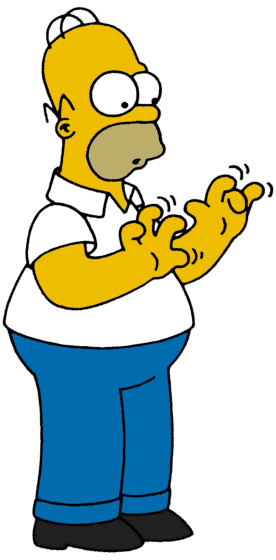

In [5]:
tf.keras.preprocessing.image.load_img('./homer_bart_2/training_set/homer/homer100.bmp')

## Train and test set

In [6]:
test_hashes = {hashlib.sha256(path.read_bytes()).digest() for path in Path('homer_bart_2/test_set').rglob('*.bmp')}
seen_hashes = set(test_hashes)
training_rows = []

for image_path in sorted(Path('homer_bart_2/training_set').rglob('*.bmp')):
    digest = hashlib.sha256(image_path.read_bytes()).digest()
    if digest not in seen_hashes:
        training_rows.append({'filename': str(image_path), 'class': image_path.parent.name})
        seen_hashes.add(digest)

training_frame = pd.DataFrame(training_rows)
train_frame, validation_frame = train_test_split(
    training_frame,
    test_size=0.2,
    random_state=1,
    stratify=training_frame['class'],
)

# Only training images receive random augmentation
training_generator = ImageDataGenerator(
    rescale=1./255,
    rotation_range=7,
    horizontal_flip=True,
    zoom_range=0.2
)
train_dataset = training_generator.flow_from_dataframe(
    train_frame,
    x_col='filename', y_col='class', classes=['bart', 'homer'],
    target_size=(64, 64),
    batch_size=8,
    class_mode='categorical',
    seed=1,
    shuffle=True,
)

validation_generator = ImageDataGenerator(rescale=1./255)
validation_dataset = validation_generator.flow_from_dataframe(
    validation_frame,
    x_col='filename', y_col='class', classes=['bart', 'homer'],
    target_size=(64, 64),
    batch_size=8,
    class_mode='categorical',
    shuffle=False,
)

Found 169 validated image filenames belonging to 2 classes.
Found 43 validated image filenames belonging to 2 classes.


In [7]:
train_dataset.classes

[0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0]

In [8]:
train_dataset.class_indices

{'bart': 0, 'homer': 1}

In [9]:
# To test, we set this parameter to false because when testing, the order of the images makes no difference.
# If we leave the value equals true, we will not be able to associate the predictions with the expected outputs
test_generator = ImageDataGenerator(rescale=1./255)
test_dataset = test_generator.flow_from_directory(
    './homer_bart_2/test_set',
    target_size = (64, 64),
    batch_size = 1,
    class_mode = 'categorical',
    shuffle = False
)

Found 54 images belonging to 2 classes.


## Building and training the neural network

In [10]:
64 * 64

4096

In [11]:
# Deeper blocks learn more channels: 32 -> 64 -> 128.
# Three convolution / pooling blocks leave 6 x 6 x 128 features.
6 * 6 * 128

4608

In [44]:
network = Sequential()
network.add(Input(shape=(64, 64, 3)))
network.add(Conv2D(32, (3,3), activation='relu'))
network.add(MaxPooling2D(pool_size=(2,2)))

network.add(Conv2D(64, (3,3), activation='relu'))
network.add(MaxPooling2D(pool_size=(2,2)))

network.add(Conv2D(128, (3,3), activation='relu'))
network.add(MaxPooling2D(pool_size=(2,2)))

network.add(Flatten())

# Small, regularized dense layers suit this small training set.
network.add(Dense(units=128, activation='relu'))
network.add(Dropout(0.3))
network.add(Dense(units=64, activation='relu'))
network.add(Dropout(0.3))
network.add(Dense(units = 2, activation='softmax'))

In [13]:
6 * 6 * 128

4608

In [14]:
network.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 691,586 (2.64 MB)

 Trainable params: 691,586 (2.64 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
network.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

In [16]:
# Give both classes equal total weight using only training labels.
class_counts = np.bincount(train_dataset.classes)
class_weights = {index: train_dataset.samples / (len(class_counts) * count)
                 for index, count in enumerate(class_counts)}

# Keep the weights that generalize best on validation data.
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True,
)
history = network.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=[early_stopping],
    class_weight=class_weights,
)
best_epoch = int(np.argmin(history.history['val_loss'])) + 1
print(f'Using weights from epoch {best_epoch} (lowest validation loss).')

Epoch 1/50


I0000 00:00:1793461868.173040   27307 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - accuracy: 0.4734 - loss: 0.7140 - val_accuracy: 0.6047 - val_loss: 0.6774
Epoch 2/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.4675 - loss: 0.7010 - val_accuracy: 0.6047 - val_loss: 0.6754
Epoch 3/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.4556 - loss: 0.6904 - val_accuracy: 0.3953 - val_loss: 0.6904
Epoch 4/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.5444 - loss: 0.6814 - val_accuracy: 0.5814 - val_loss: 0.6487
Epoch 5/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 71ms/step - accuracy: 0.5799 - loss: 0.6721 - val_accuracy: 0.7907 - val_loss: 0.6271
Epoch 6/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 62ms/step - accuracy: 0.6805 - loss: 0.6419 - val_accuracy: 0.6512 - val_loss: 0.6274
Epoch 7/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.5621 - loss: 0.6819 - val_accuracy: 0.8372 - val_loss: 0.5876
Epoch 8/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.7101 - loss: 0.6236 - val_accuracy: 0.8372 - val_loss: 0.

## Evaluating the neural network

In [17]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

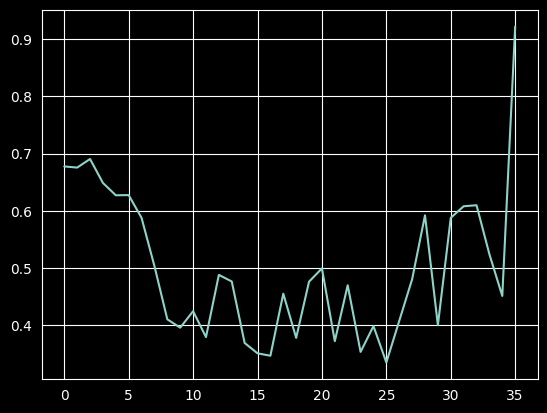

In [18]:
plt.plot(history.history['val_loss']);

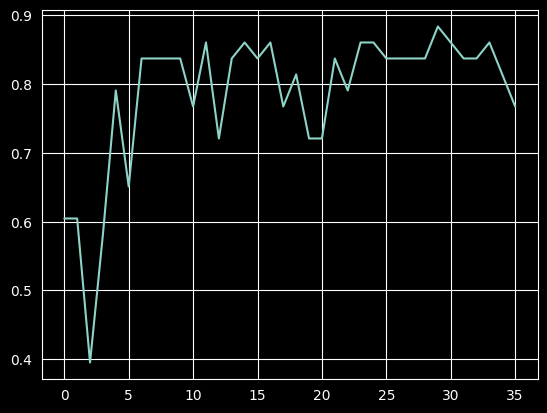

In [19]:
plt.plot(history.history['val_accuracy']);

In [20]:
test_dataset.class_indices

{'bart': 0, 'homer': 1}

In [21]:
test_dataset.reset()
test_probabilities = network.predict(test_dataset)
test_probabilities

54/54 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step 


array([[9.99875546e-01, 1.24462968e-04],
       [1.00000000e+00, 4.72710049e-08],
       [5.85323572e-01, 4.14676428e-01],
       [1.00000000e+00, 8.55916316e-09],
       [9.99999881e-01, 7.68249109e-08],
       [1.00000000e+00, 1.44957841e-08],
       [9.99599636e-01, 4.00434714e-04],
       [3.25652093e-01, 6.74347878e-01],
       [5.80212712e-01, 4.19787288e-01],
       [4.03543830e-01, 5.96456230e-01],
       [5.00007153e-01, 4.99992877e-01],
       [9.99996781e-01, 3.20397112e-06],
       [9.75489199e-01, 2.45107953e-02],
       [9.96080339e-01, 3.91966291e-03],
       [9.96460497e-01, 3.53954243e-03],
       [1.00000000e+00, 3.56011436e-11],
       [4.81896475e-02, 9.51810300e-01],
       [9.99999642e-01, 3.15569253e-07],
       [7.47222602e-01, 2.52777368e-01],
       [1.00000000e+00, 6.77870815e-10],
       [9.96175528e-01, 3.82445450e-03],
       [9.99921083e-01, 7.88659308e-05],
       [9.03228462e-01, 9.67715457e-02],
       [1.01747043e-01, 8.98252904e-01],
       [9.999998

In [22]:
predictions = np.argmax(test_probabilities, axis=1)
predictions

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 1])

In [23]:
test_dataset.classes

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=int32)

In [24]:
from sklearn.metrics import accuracy_score
accuracy_score(test_dataset.classes, predictions)

0.8703703703703703

In [25]:
test_dataset.class_indices

{'bart': 0, 'homer': 1}

<Axes: >

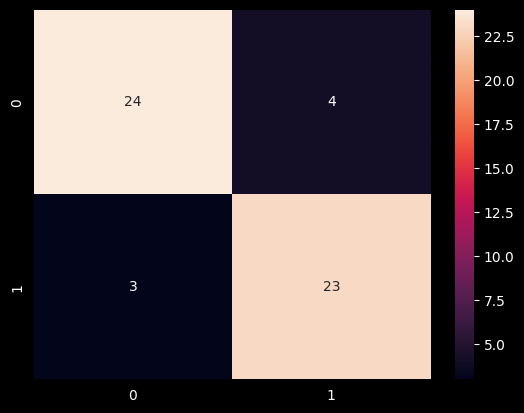

In [26]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(test_dataset.classes, predictions)
sns.heatmap(cm, annot=True)

In [27]:
from sklearn.metrics import classification_report
class_names = list(test_dataset.class_indices)
print(classification_report(test_dataset.classes, predictions, labels=range(len(class_names)), target_names=class_names, zero_division=0))

              precision    recall  f1-score   support

        bart       0.89      0.86      0.87        28
       homer       0.85      0.88      0.87        26

    accuracy                           0.87        54
   macro avg       0.87      0.87      0.87        54
weighted avg       0.87      0.87      0.87        54



## Saving and loading the model

In [28]:
model_json = network.to_json()
with open('network.json','w') as json_file:
  json_file.write(model_json)

In [29]:
network.save_weights('network.weights.h5')

In [30]:
with open('network.json', 'r') as json_file:
  json_saved_model = json_file.read()
json_saved_model

'{"module": "keras", "class_name": "Sequential", "config": {"name": "sequential", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "layers": [{"module": "keras.layers", "class_name": "InputLayer", "config": {"batch_shape": [null, 64, 64, 3], "dtype": "float32", "sparse": false, "ragged": false, "name": "input_layer", "optional": false}, "registered_name": null}, {"module": "keras.layers", "class_name": "Conv2D", "config": {"name": "conv2d", "trainable": true, "dtype": {"module": "keras", "class_name": "DTypePolicy", "config": {"name": "float32"}, "registered_name": null}, "filters": 32, "kernel_size": [3, 3], "strides": [1, 1], "padding": "valid", "data_format": "channels_last", "dilation_rate": [1, 1], "groups": 1, "activation": "relu", "use_bias": true, "kernel_initializer": {"module": "keras.initializers", "class_name": "GlorotUniform", "config": {"seed": null, "input_axes": null, "output_axes": nul

In [31]:
network_loaded = tf.keras.models.model_from_json(json_saved_model)
network_loaded.load_weights('network.weights.h5')
network_loaded.compile(
    loss='categorical_crossentropy',
    optimizer='Adam',
    metrics=['accuracy']
)

In [32]:
network_loaded.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 691,586 (2.64 MB)

 Trainable params: 691,586 (2.64 MB)

 Non-trainable params: 0 (0.00 B)

## Classifying one single image

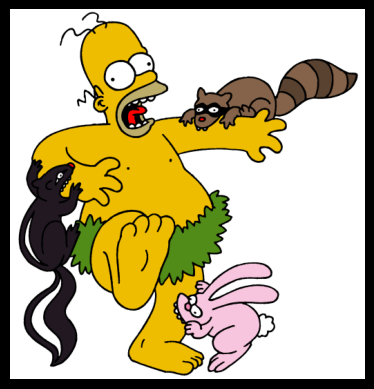

In [33]:
image_path = Path('homer_bart_2/test_set/homer/homer15.bmp')
original_image = cv2.imread(str(image_path))
if original_image is None:
    raise ValueError(f'Could not read image: {image_path}')
display_image(original_image)

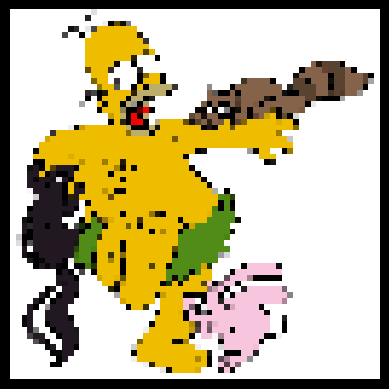

In [34]:
resized_image = cv2.resize(original_image, (64, 64), interpolation=cv2.INTER_NEAREST_EXACT)
display_image(resized_image)

In [35]:
resized_image

array([[[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       ...,

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]],

       [[255, 255, 255],
        [255, 255, 255],
        [255, 255, 255],
        ...,
        [255, 255, 255],
        [255, 255, 255],
        [255, 255, 255]]

In [36]:
# Always preprocess from the uint8 image, so rerunning this cell is safe
image = cv2.cvtColor(resized_image, cv2.COLOR_BGR2RGB).astype(np.float32) / 255.0
image

array([[[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       ...,

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]],

       [[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        ...,
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]]], shape=(64, 64, 3), dtype=float32)

In [37]:
image.shape

(64, 64, 3)

In [38]:
image_batch = np.expand_dims(image, axis=0)
image_batch.shape

(1, 64, 64, 3)

In [39]:
probabilities = network_loaded(image_batch, training=False).numpy()[0]
probabilities

array([0.15555212, 0.84444785], dtype=float32)

In [40]:
predicted_class = int(np.argmax(probabilities))
predicted_class

1

In [41]:
test_dataset.class_indices

{'bart': 0, 'homer': 1}

In [42]:
class_names = {index: name for name, index in test_dataset.class_indices.items()}
predicted_label = class_names[predicted_class]
print(f'Predicted: {predicted_label.capitalize()} ({probabilities[predicted_class]:.2%})')
print(f'Expected: {image_path.parent.name.capitalize()}')

Predicted: Homer (84.44%)
Expected: Homer
